# do-mpc Step-by-Step Results

This notebook walks through the repository's existing do-mpc NMPC path, from loading the saved model to reviewing each simulated control decision.

> **Scope:** This is a synthetic mismatched-plant experiment. The neural network is static, and the controller uses an explicit, uncalibrated first-order lag wrapper. This is not plant validation, production control, or a deployment recommendation. Solver candidates are not applied without the independent governance gate. No plant-write interface exists.

Run the cells from top to bottom. The final replay uses 12 steps from one held-out input scenario.

## 1. Set Up Notebook Environment

Locate the project root from the notebook's current folder, import the supported package APIs, and set compact table display options.

In [24]:
from importlib.metadata import version
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 60)

cwd = Path.cwd().resolve()
ROOT = next(
    (path for path in (cwd, *cwd.parents) if (path / "configs" / "mpc.yaml").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the neural-network-inverse-optimization project.")

sys.path.insert(0, str(ROOT / "src"))

from nn_optimization.cli import select_scenarios
from nn_optimization.model import load_config, load_model
from nn_optimization.mpc import ForecastProvider, MPCController
from nn_optimization.simulation import load_original_plant

print(f"Project root: {ROOT}")
print(f"do-mpc distribution version: {version('do_mpc')}")
print("Step 1 result: notebook environment and repository APIs are ready.")

Project root: C:\Users\jaco238653\OneDrive - Hatch LTD\Documents\Python\NN_Optimization\neural-network-inverse-optimization
do-mpc distribution version: 5.1.2
Step 1 result: notebook environment and repository APIs are ready.


## 2. Define Input Data for the Walkthrough

Load the saved checkpoint and YAML settings. Select the first held-out scenario that satisfies the configured model and actuator envelopes, then calculate the original synthetic plant's initial noise-free CVs.

In [25]:
from nn_optimization.optimization import problem_from_config

predictor, training_data, support_lower, support_upper = load_model(
    ROOT, ROOT / "configs" / "model.yaml"
)
inverse_config = load_config(ROOT / "configs" / "inverse_optimization.yaml")
mpc_config = load_config(ROOT / "configs" / "mpc.yaml")
problem = problem_from_config(predictor, inverse_config, support_lower, support_upper)
contract = predictor.contract

configuration = pd.DataFrame(
    {
        "setting": ["model inputs", "model outputs", "MPC horizon", "sample interval", "wrapper alpha", "simulation steps"],
        "value": [
            ", ".join(contract.input_names),
            ", ".join(contract.output_names),
            mpc_config["n_horizon"],
            mpc_config["t_step"],
            mpc_config["alpha"],
            12,
        ],
    }
)
display(configuration)
print("Model contract and configuration loaded.")

,setting,value
0,model inputs,"d1_feed_grade, d2_hardness, d3_moisture, d4_impurity, d5..."
1,model outputs,"y1_quality, y2_energy_load"
2,MPC horizon,8
3,sample interval,1.0
4,wrapper alpha,"[0.11750309741540454, 0.06449301496838222]"
5,simulation steps,12


Model contract and configuration loaded.


In [26]:
disturbance, previous_mv = select_scenarios(problem, training_data, count=1)[0]
plant = load_original_plant(ROOT)
initial_cv = np.asarray(plant(disturbance[None, :], previous_mv[None, :]))[0]
input_row = contract.assemble(previous_mv, disturbance)

scenario_table = pd.DataFrame(
    {"signal": contract.input_names, "role value": input_row}
)
initial_outputs = pd.DataFrame(
    {
        "output": contract.output_names,
        "initial synthetic CV": initial_cv,
        "static model at scenario": predictor.predict(input_row),
        "target": problem.target,
    }
)
print("Selected held-out operating scenario:")
display(scenario_table)
print("Starting outputs before the first simulated control move:")
display(initial_outputs)
print("The held-out input is selected by the same envelope checks used by the CLI.")

Selected held-out operating scenario:


,signal,role value
0,d1_feed_grade,1.229148
1,d2_hardness,69.325734
2,d3_moisture,7.794155
3,d4_impurity,2.268251
4,d5_ambient,18.514345
5,u1_feed_rate,110.553557
6,u2_water_rate,87.149308
7,u3_reagent_rate,4.172912
8,u4_speed,78.158500
9,u5_temperature_setpoint,66.109372


Starting outputs before the first simulated control move:


,output,initial synthetic CV,static model at scenario,target
0,y1_quality,86.447807,85.595901,87.395050
1,y2_energy_load,71.138975,71.033981,71.557525


The held-out input is selected by the same envelope checks used by the CLI.


## 3. Run Step 1 and Capture Output

Build aligned disturbance and target forecasts. The controller requires N+1 rows for an N-step horizon. Then make one solve and inspect its candidate move and predicted horizon.

In [27]:
sample_interval = mpc_config["t_step"]
horizon = mpc_config["n_horizon"]
disturbance_provider = ForecastProvider.constant(disturbance, sample_interval=sample_interval)
target_after = problem.target + contract.output_scale * np.asarray(
    mpc_config["target_step_standard_deviations"]
)
target_provider = ForecastProvider.step(
    problem.target,
    target_after,
    at_sample=mpc_config["target_step_sample"],
    sample_interval=sample_interval,
)

disturbance_rows = disturbance_provider.horizon(0, horizon)
target_rows = target_provider.horizon(0, horizon)
forecast_values = np.column_stack(
    [np.arange(horizon + 1), disturbance_rows, target_rows]
)
forecast_columns = [
    f"DV: {signal['name']}" for signal in contract.metadata["inputs"] if signal["role"] == "DV"
]
forecast_table = pd.DataFrame(
    forecast_values,
    columns=["forecast step", *forecast_columns, *[f"target CV: {name}" for name in contract.output_names]],
)
print(f"Forecast rows: {len(forecast_table)} (expected N+1 = {horizon + 1})")
display(forecast_table)

controller = MPCController(problem, mpc_config, disturbance_provider, target_provider)
candidate = controller.step(initial_cv, previous_mv)
horizon_controls = pd.DataFrame(
    candidate.diagnostics["horizon_mv"],
    columns=[contract.input_names[index] for index in contract.mv_indices],
)
print("Candidate control trajectory from the first horizon solve:")
display(horizon_controls)
print("One-step solver result (candidate only; not governance-approved):")
display(
    pd.Series(
        {
            "solver status": candidate.status,
            "solver success": candidate.success,
            "feasible": candidate.feasible,
            "iterations": candidate.iterations,
            "objective": candidate.objective,
            "candidate MV": candidate.controls.tolist(),
            "predicted next CV": candidate.outputs.tolist(),
            "soft slacks": candidate.diagnostics["soft_slacks"],
        },
        name="result",
    ).to_frame()
)

Forecast rows: 9 (expected N+1 = 9)


,forecast step,DV: d1_feed_grade,DV: d2_hardness,DV: d3_moisture,DV: d4_impurity,DV: d5_ambient,target CV: y1_quality,target CV: y2_energy_load
0,0.0,1.229148,69.325734,7.794155,2.268251,18.514345,87.395050,71.557525
1,1.0,1.229148,69.325734,7.794155,2.268251,18.514345,87.395050,71.557525
2,2.0,1.229148,69.325734,7.794155,2.268251,18.514345,87.395050,71.557525
3,3.0,1.229148,69.325734,7.794155,2.268251,18.514345,87.395050,71.557525
4,4.0,1.229148,69.325734,7.794155,2.268251,18.514345,87.395050,71.557525
5,5.0,1.229148,69.325734,7.794155,2.268251,18.514345,87.395050,71.557525
6,6.0,1.229148,69.325734,7.794155,2.268251,18.514345,87.728897,71.263726
7,7.0,1.229148,69.325734,7.794155,2.268251,18.514345,87.728897,71.263726
8,8.0,1.229148,69.325734,7.794155,2.268251,18.514345,87.728897,71.263726


Candidate control trajectory from the first horizon solve:


c:\Users\jaco238653\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\casadi\casadi.py:913: FutureWarning: 
casadi: a numpy function was called on a casadi value (issue #2959).
This used legacy casadi 3.7.2 behaviour, where the result type follows
the input:
  - a numeric input (DM)       -> a plain numpy array
  - a symbolic input (SX / MX) -> a casadi value, or an error if the
                                  function has no casadi equivalent

For a shape-correct, type-preserving result, opt in to the
casadi-aware numpy support:

    try:
        ca.GlobalOptions.setNumpyMode(1)
    except AttributeError:
        pass

Or use setNumpyMode(-1) to keep legacy behaviour silently.
Shown once; run python with -W always to see every occurrence.

  _w.warn(_NUMPY_LEGACY_NOTICE, FutureWarning)


,u1_feed_rate,u2_water_rate,u3_reagent_rate,u4_speed,u5_temperature_setpoint
0,111.560356,86.384643,4.222878,78.528985,66.379874
1,112.567155,85.619977,4.272844,78.899470,66.650375
2,113.573953,84.871551,4.297807,79.269955,66.920876
3,114.580752,84.493379,4.297807,79.640440,66.952917
4,115.587551,84.247892,4.297807,80.010925,66.952917
5,116.594349,84.091212,4.297807,80.381410,66.952917
6,117.601148,84.088176,4.297807,80.751895,66.952917
7,118.607947,84.166411,4.297807,81.122380,66.952917


One-step solver result (candidate only; not governance-approved):


,result
solver status,Solve_Succeeded
solver success,True
feasible,True
iterations,17
objective,0.273685
candidate MV,"[111.56035580332477, 86.38464258365332, 4.22287821916449..."
predicted next CV,"[86.39492744703944, 71.14048875292951]"
soft slacks,"[8.83110787212974e-06, 8.861626672185868e-06, 8.86259335..."


## 4. Run Step 2 and Compare With Step 1

Run the existing synthetic closed-loop simulator. It starts a fresh do-mpc controller and routes each candidate through `ValidationGate`; the applied MV can differ from the solver candidate if the gate rejects it.

In [28]:
from nn_optimization.simulation import simulate

STEP_COUNT = 12
frame = simulate(
    problem,
    mpc_config,
    inverse_config,
    disturbance,
    previous_mv,
    initial_cv,
    plant,
    STEP_COUNT,
    policy="NMPC",
    disturbance_provider=disturbance_provider,
    target_provider=target_provider,
)

step_columns = [
    "sample",
    "solver_status",
    "accepted",
    "fallback_tier",
    "rejection_reason",
    "controls",
    "predicted_cv",
    "measured_cv",
    "target",
    "objective",
    "runtime",
    "hard_cv_violation",
    "slack_max",
]
print(f"Closed-loop replay: {len(frame)} steps")
display(frame[step_columns])

first_applied_mv = np.asarray(frame.iloc[0]["controls"])
first_measured_cv = np.asarray(frame.iloc[0]["measured_cv"])
first_comparison = pd.DataFrame(
    {
        "signal": [*[contract.input_names[index] for index in contract.mv_indices], *contract.output_names],
        "one-solve candidate": [*candidate.controls, *candidate.outputs],
        "first gated replay result": [*first_applied_mv, *first_measured_cv],
    }
)
print("Step 1 candidate compared with the first gated/applied replay result:")
display(first_comparison)

c:\Users\jaco238653\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\casadi\casadi.py:913: FutureWarning: 
casadi: a numpy function was called on a casadi value (issue #2959).
This used legacy casadi 3.7.2 behaviour, where the result type follows
the input:
  - a numeric input (DM)       -> a plain numpy array
  - a symbolic input (SX / MX) -> a casadi value, or an error if the
                                  function has no casadi equivalent

For a shape-correct, type-preserving result, opt in to the
casadi-aware numpy support:

    try:
        ca.GlobalOptions.setNumpyMode(1)
    except AttributeError:
        pass

Or use setNumpyMode(-1) to keep legacy behaviour silently.
Shown once; run python with -W always to see every occurrence.

  _w.warn(_NUMPY_LEGACY_NOTICE, FutureWarning)


Closed-loop replay: 12 steps


,sample,solver_status,accepted,fallback_tier,rejection_reason,controls,predicted_cv,measured_cv,target,objective,runtime,hard_cv_violation,slack_max
0,0,Solve_Succeeded,True,optimizer_recommendation,None,"[111.56035580332477, 86.38464258365332, 4.22287821916449...","[86.39492744703944, 71.14048875292951]","[86.46597050578468, 71.12935448286572]","[87.3950495889512, 71.55752545570665]",0.273685,0.063334,0.0,0.000009
1,1,Solve_Succeeded,True,optimizer_recommendation,None,"[112.56715450701428, 85.61997713799893, 4.27284408731749...","[86.45997356696215, 71.14025168729725]","[86.49584435922306, 71.19381596865406]","[87.3950495889512, 71.55752545570665]",0.189472,0.038454,0.0,0.000014
2,2,Solve_Succeeded,True,optimizer_recommendation,None,"[113.57395320920362, 84.85531180916423, 4.29780738723245...","[86.53156524151734, 71.20874210116577]","[86.46266925563816, 71.1888308681096]","[87.3950495889512, 71.55752545570665]",0.120211,0.035185,0.0,0.000014
3,3,Solve_Succeeded,True,optimizer_recommendation,None,"[114.58075191651415, 84.16715102113335, 4.29780738877681...","[86.53170804571141, 71.20957607569791]","[86.51404880918297, 71.26471899775201]","[87.3950495889512, 71.55752545570665]",0.114588,0.036772,0.0,0.000009
4,4,Solve_Succeeded,True,optimizer_recommendation,None,"[115.58755062308765, 84.08817489188552, 4.29780738870681...","[86.60666968656072, 71.28974681598162]","[86.49948218909125, 71.3223245617856]","[87.3950495889512, 71.55752545570665]",0.053895,0.034058,0.0,0.000009
5,5,Solve_Succeeded,True,optimizer_recommendation,None,"[116.59434932898112, 84.08817486550747, 4.29780738864985...","[86.6241559095659, 71.35477719793332]","[86.4995468714274, 71.43576305458726]","[87.3950495889512, 71.55752545570665]",0.273205,0.033000,0.0,0.000009
6,6,Solve_Succeeded,True,optimizer_recommendation,None,"[117.60114803393283, 84.08817485417926, 4.29780738850532...","[86.65477985834895, 71.47371898710925]","[86.46068430157773, 71.5372958052322]","[87.72889747320632, 71.26372638907947]",0.328473,0.031705,0.0,0.000009
7,7,Solve_Succeeded,True,optimizer_recommendation,None,"[118.60794673797871, 84.08817484828548, 4.29780738834074...","[86.65095816349522, 71.58332563494082]","[86.44060939100581, 71.60701689223748]","[87.72889747320632, 71.26372638907947]",0.435227,0.031778,0.0,0.000009
8,8,Solve_Succeeded,True,optimizer_recommendation,None,"[119.61474544094666, 84.0881748463059, 4.297807388215650...","[86.65201160166143, 71.6565559706557]","[86.40436147373575, 71.73050823543618]","[87.72889747320632, 71.26372638907947]",0.504527,0.030906,0.0,0.000009
9,9,Solve_Succeeded,True,optimizer_recommendation,None,"[120.62154414266097, 84.08817484544751, 4.29780738815822...","[86.62793052161345, 71.77287392204033]","[86.3694566520934, 71.88392763642408]","[87.72889747320632, 71.26372638907947]",0.665043,0.035417,0.0,0.000009


Step 1 candidate compared with the first gated/applied replay result:


,signal,one-solve candidate,first gated replay result
0,u1_feed_rate,111.560356,111.560356
1,u2_water_rate,86.384643,86.384643
2,u3_reagent_rate,4.222878,4.222878
3,u4_speed,78.528985,78.528985
4,u5_temperature_setpoint,66.379874,66.379874
5,y1_quality,86.394927,86.465971
6,y2_energy_load,71.140489,71.129354


## 5. Run Step 3 and Validate Intermediate Results

Check the replay dimensions, finite values, forecast alignment, and nonnegative diagnostics. These checks validate the experiment's data and outputs; they do not certify the model or plant.

In [29]:
controls_by_step = np.asarray(frame["controls"].tolist(), dtype=float)
predicted_by_step = np.asarray(frame["predicted_cv"].tolist(), dtype=float)
measured_by_step = np.asarray(frame["measured_cv"].tolist(), dtype=float)

checks = {
    "expected replay step count": len(frame) == STEP_COUNT,
    "control array shape": controls_by_step.shape == (STEP_COUNT, len(contract.mv_indices)),
    "CV arrays have expected shape": predicted_by_step.shape == measured_by_step.shape == (STEP_COUNT, contract.n_output),
    "all objectives are finite": bool(np.isfinite(frame["objective"].to_numpy(dtype=float)).all()),
    "all controller runtimes are finite": bool(np.isfinite(frame["runtime"].to_numpy(dtype=float)).all()),
    "all hard-CV diagnostics are nonnegative": bool((frame["hard_cv_violation"] >= 0).all()),
    "forecast includes terminal row": disturbance_rows.shape[0] == target_rows.shape[0] == horizon + 1,
}
check_table = pd.DataFrame({"check": checks.keys(), "passed": checks.values()})
display(check_table)
assert all(checks.values()), "A walkthrough data-integrity check failed."

print(f"Governance accepted {int(frame['accepted'].sum())} of {STEP_COUNT} recommendations.")
print("Solver success and governance acceptance are reported separately above.")

,check,passed
0,expected replay step count,True
1,control array shape,True
2,CV arrays have expected shape,True
3,all objectives are finite,True
4,all controller runtimes are finite,True
5,all hard-CV diagnostics are nonnegative,True
6,forecast includes terminal row,True


Governance accepted 12 of 12 recommendations.
Solver success and governance acceptance are reported separately above.


## 6. Aggregate All Step Results in a Summary Table

Keep the row-level solver and governance outcomes, then append one aggregate row with key run metrics.

In [30]:
from nn_optimization.benchmarking import closed_loop_metrics

metrics = closed_loop_metrics(frame, sample_interval)
summary_table = frame[
    ["sample", "solver_status", "accepted", "fallback_tier", "objective", "runtime", "hard_cv_violation", "slack_max"]
].copy()
summary_table.insert(0, "record", "step")
summary_table["step_count"] = 1

aggregate_row = {
    "record": "aggregate",
    "sample": "all",
    "solver_status": "per-step rows above",
    "accepted": bool(frame["accepted"].all()),
    "fallback_tier": ", ".join(sorted(set(frame["fallback_tier"].astype(str)))),
    "objective": metrics["mean_objective"],
    "runtime": metrics["runtime_p50"],
    "hard_cv_violation": float(frame["hard_cv_violation"].max()),
    "slack_max": float(frame["slack_max"].max()),
    "step_count": metrics["steps"],
}
summary_table = pd.concat([summary_table, pd.DataFrame([aggregate_row])], ignore_index=True)
display(summary_table)

print("Aggregate closed-loop metrics:")
display(pd.Series(metrics, name="value").to_frame())

,record,sample,solver_status,accepted,fallback_tier,objective,runtime,hard_cv_violation,slack_max,step_count
0,step,0,Solve_Succeeded,True,optimizer_recommendation,0.273685,0.063334,0.0,0.000009,1
1,step,1,Solve_Succeeded,True,optimizer_recommendation,0.189472,0.038454,0.0,0.000014,1
2,step,2,Solve_Succeeded,True,optimizer_recommendation,0.120211,0.035185,0.0,0.000014,1
3,step,3,Solve_Succeeded,True,optimizer_recommendation,0.114588,0.036772,0.0,0.000009,1
4,step,4,Solve_Succeeded,True,optimizer_recommendation,0.053895,0.034058,0.0,0.000009,1
5,step,5,Solve_Succeeded,True,optimizer_recommendation,0.273205,0.033000,0.0,0.000009,1
6,step,6,Solve_Succeeded,True,optimizer_recommendation,0.328473,0.031705,0.0,0.000009,1
7,step,7,Solve_Succeeded,True,optimizer_recommendation,0.435227,0.031778,0.0,0.000009,1
8,step,8,Solve_Succeeded,True,optimizer_recommendation,0.504527,0.030906,0.0,0.000009,1
9,step,9,Solve_Succeeded,True,optimizer_recommendation,0.665043,0.035417,0.0,0.000009,1


Aggregate closed-loop metrics:


,value
steps,12
integrated_absolute_error,18.762343
total_mv_travel,19.461271
hard_cv_violation_steps,0
governance_rejections,0
runtime_p50,0.035301
runtime_p95,0.051107
final_predicted_cv,"[86.53334563150639, 72.0323094685688]"
mean_objective,0.413714


## 7. Visualize Step-by-Step Changes

Compare model predictions with the noisy, lagged synthetic measurements and configured CV targets. The second panel shows applied MVs; the final panel shows objective and hard-CV violation by sample.

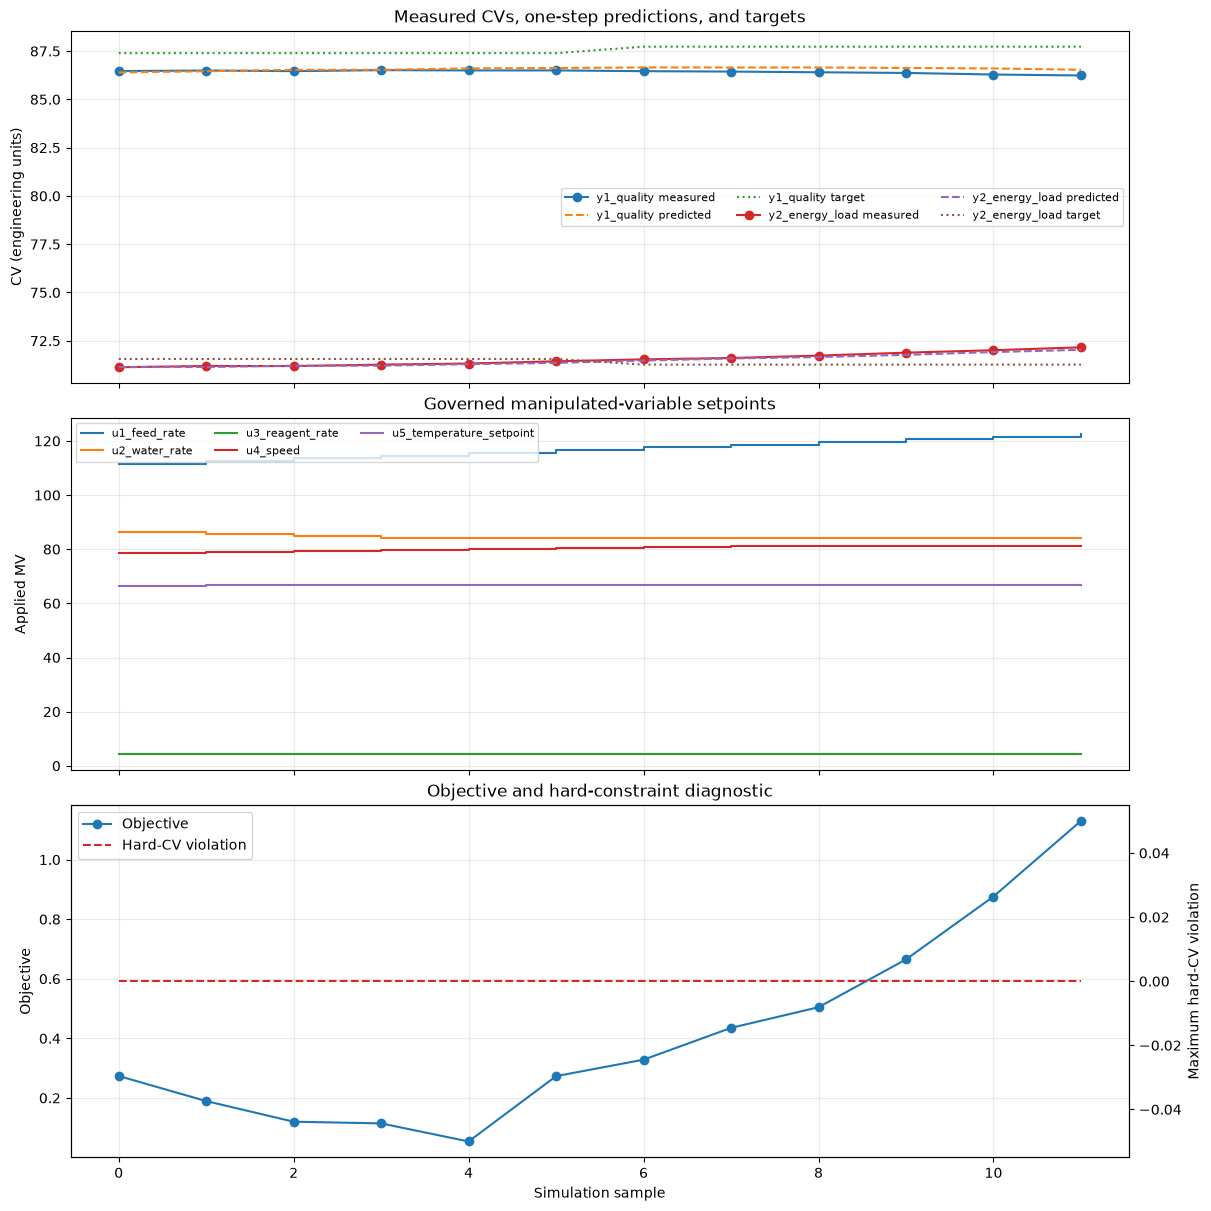

In [ ]:
import matplotlib.pyplot as plt

samples = frame["sample"].to_numpy()
measured_values = np.asarray(frame["measured_cv"].tolist(), dtype=float)
predicted_values = np.asarray(frame["predicted_cv"].tolist(), dtype=float)
target_values = np.asarray(frame["target"].tolist(), dtype=float)
control_values = np.asarray(frame["controls"].tolist(), dtype=float)

fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True, constrained_layout=True)
for index, output_name in enumerate(contract.output_names):
    axes[0].plot(samples, measured_values[:, index], marker="o", label=f"{output_name} measured")
    axes[0].plot(samples, predicted_values[:, index], linestyle="--", label=f"{output_name} predicted")
    axes[0].plot(samples, target_values[:, index], linestyle=":", label=f"{output_name} target")
axes[0].set_ylabel("CV (engineering units)")
axes[0].set_title("Measured CVs, one-step predictions, and targets")
axes[0].legend(ncol=3, fontsize=8)
axes[0].grid(alpha=0.25)

for index, mv_name in enumerate([contract.input_names[i] for i in contract.mv_indices]):
    axes[1].step(samples, control_values[:, index], where="post", label=mv_name)
axes[1].set_ylabel("Applied MV")
axes[1].set_title("Governed manipulated-variable setpoints")
axes[1].legend(ncol=3, fontsize=8)
axes[1].grid(alpha=0.25)

axes[2].plot(samples, frame["objective"], marker="o", color="tab:blue", label="Objective")
axes[2].set_ylabel("Objective")
axes[2].set_xlabel("Simulation sample")
axes[2].grid(alpha=0.25)
violation_axis = axes[2].twinx()
violation_axis.plot(
    samples,
    frame["hard_cv_violation"],
    linestyle="--",
    color="tab:red",
    label="Hard-CV violation",
)
violation_axis.set_ylabel("Maximum hard-CV violation")
handles, labels = axes[2].get_legend_handles_labels()
violation_handles, violation_labels = violation_axis.get_legend_handles_labels()
axes[2].legend(handles + violation_handles, labels + violation_labels, loc="best")
axes[2].set_title("Objective and hard-constraint diagnostic")

plt.show()

## 8. Export Final Results

Write the per-step replay and combined summary to a unique run folder under `results/aipc/`. This avoids overwriting prior results.

In [32]:
from datetime import datetime

run_tag = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
export_dir = ROOT / "results" / "aipc" / "notebook_runs"
export_dir.mkdir(parents=True, exist_ok=True)
steps_path = export_dir / f"do_mpc_walkthrough_{run_tag}_steps.csv"
summary_path = export_dir / f"do_mpc_walkthrough_{run_tag}_summary.csv"

frame.to_csv(steps_path, index=False)
summary_table.to_csv(summary_path, index=False)
print(f"Step results: {steps_path}")
print(f"Summary table: {summary_path}")

Step results: C:\Users\jaco238653\OneDrive - Hatch LTD\Documents\Python\NN_Optimization\neural-network-inverse-optimization\results\aipc\notebook_runs\do_mpc_walkthrough_20261026_140744_277029_steps.csv
Summary table: C:\Users\jaco238653\OneDrive - Hatch LTD\Documents\Python\NN_Optimization\neural-network-inverse-optimization\results\aipc\notebook_runs\do_mpc_walkthrough_20261026_140744_277029_summary.csv


## Interpretation

- A successful solver status describes the numerical solve. `accepted` and `fallback_tier` describe the independent governance decision.
- The temporary lag model does not identify real process dynamics. Differences between predicted and measured CVs are expected in this deliberately mismatched, noisy replay.
- The results demonstrate code behavior on synthetic data only. They do not establish plant performance, safety, or readiness for deployment.